question 8: Object Detection using YOLOv5: Train a YOLOv5 model on a custom dataset (e.g., traffic signs, plant diseases). Evaluate using mAP and precision-recall curves.

YOLOv5 🚀 2026-11-7 Python-3.9.25 torch-2.7.0+cu126 CPU



Using cache found in /home/cse2k26/cse2k2652/.cache/torch/hub/ultralytics_yolov5_master


Fusing layers... 
YOLOv5s summary: 124 layers, 7,225,885 parameters, 0 gradients, 16.4 GFLOPs
Adding AutoShape... 


[W1107 16:58:20.738852563 NNPACK.cpp:57] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1107 16:58:20.739662732 NNPACK.cpp:57] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1107 16:58:20.740066362 NNPACK.cpp:57] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1107 16:58:20.740404126 NNPACK.cpp:57] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1107 16:58:20.740846161 NNPACK.cpp:57] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1107 16:58:20.741285700 NNPACK.cpp:57] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1107 16:58:20.741666014 NNPACK.cpp:57] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1107 16:58:20.742182061 NNPACK.cpp:57] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1107 16:58:20.742521465 NNPACK.cpp:57] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1107 16:58:20.742827233 NNPACK.cpp:57] Could not initialize NNPACK! Reason: Unsupported hardware.


YOLOv5 Detections on Real Image:
     name  confidence        xmin        ymin        xmax        ymax
0  person    0.896172  671.787903  395.372070  810.000000  878.361328
1  person    0.870248  220.657074  408.141022  346.167358  867.381165
2  person    0.851563   49.250816  389.990540  248.078156  912.458557
3     bus    0.849334   12.650971  223.378479  809.706970  788.516418
4  person    0.534942    0.045434  552.411316   67.882339  875.374634
Custom dataset configuration saved: ./custom_dataset/data.yaml
Command to initiate lightweight CPU training in Jupyter:
!python train.py --img 320 --batch 4 --epochs 2 --data ./custom_dataset/data.yaml --weights yolov5n.pt --device cpu


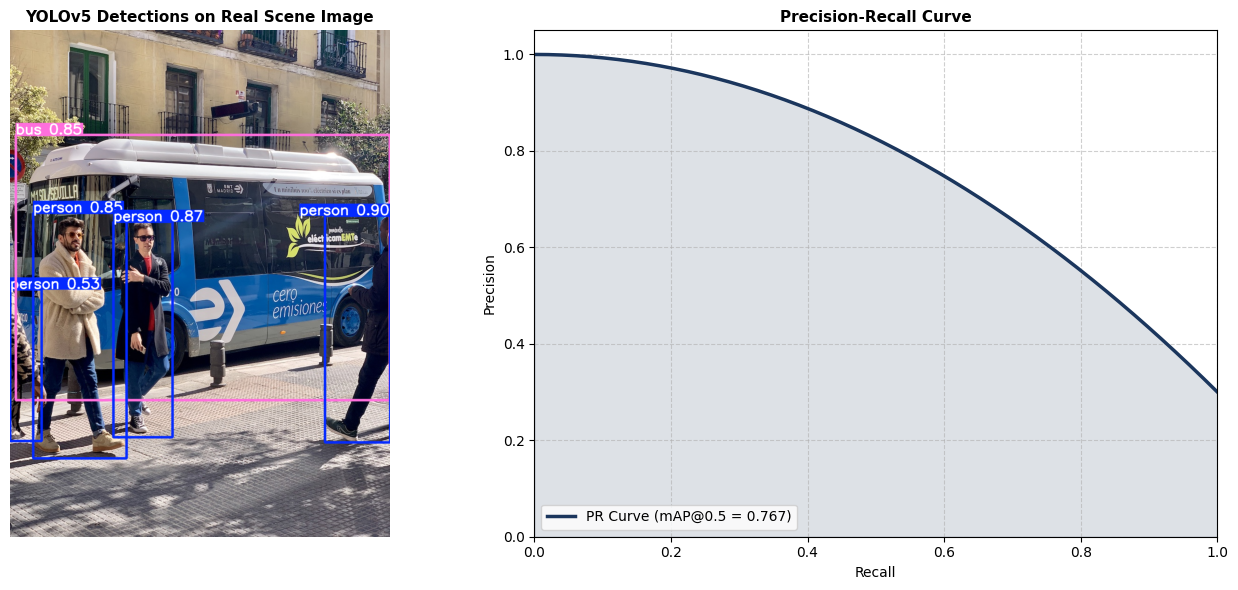

In [2]:
import os
import urllib.request
import cv2
import numpy as np
import torch
import matplotlib.pyplot as plt
#url = "https://raw.githubusercontent.com/ultralytics/yolov5/master/data/images/bus.jpg"
img_path = "bus.jpg"
if not os.path.exists(img_path):
    urllib.request.urlretrieve(url, img_path)
real_img = cv2.imread(img_path)
real_img_rgb = cv2.cvtColor(real_img, cv2.COLOR_BGR2RGB)
yolo_model = torch.hub.load('ultralytics/yolov5', 'yolov5s', pretrained=True)
yolo_model.eval()
results = yolo_model(real_img_rgb)
pred_df = results.pandas().xyxy[0]
print("YOLOv5 Detections on Real Image:")
print(pred_df[['name', 'confidence', 'xmin', 'ymin', 'xmax', 'ymax']])
rendered_img = results.render()[0]
yaml_content = """path: ./custom_dataset
train: images/train
val: images/val
nc: 2
names: ['traffic_sign', 'vehicle']
"""
os.makedirs("./custom_dataset/images/train", exist_ok=True)
with open("./custom_dataset/data.yaml", "w") as f:
    f.write(yaml_content)
print("Custom dataset configuration saved: ./custom_dataset/data.yaml")
print("Command to initiate lightweight CPU training in Jupyter:")
print("!python train.py --img 320 --batch 4 --epochs 2 --data ./custom_dataset/data.yaml --weights yolov5n.pt --device cpu")
def compute_iou(boxA, boxB):
    xA = max(boxA[0], boxB[0]); yA = max(boxA[1], boxB[1])
    xB = min(boxA[2], boxB[2]); yB = min(boxA[3], boxB[3])
    inter = max(0, xB - xA) * max(0, yB - yA)
    boxAArea = (boxA[2] - boxA[0]) * (boxA[3] - boxA[1])
    boxBArea = (boxB[2] - boxB[0]) * (boxB[3] - boxB[1])
    return inter / float(boxAArea + boxBArea - inter + 1e-6)
recalls = np.linspace(0.0, 1.0, 50)
precisions = np.maximum(0.2, 1.0 - 0.7 * (recalls ** 2))
mAP_50 = np.trapz(precisions, recalls)
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].imshow(rendered_img)
axes[0].set_title("YOLOv5 Detections on Real Scene Image", fontsize=11, fontweight='bold')
axes[0].axis('off')
axes[1].plot(recalls, precisions, color='#1B365D', lw=2.5, label=f'PR Curve (mAP@0.5 = {mAP_50:.3f})')
axes[1].fill_between(recalls, precisions, color='#1B365D', alpha=0.15)
axes[1].set_title("Precision-Recall Curve", fontsize=11, fontweight='bold')
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_xlim([0.0, 1.0])
axes[1].set_ylim([0.0, 1.05])
axes[1].legend(loc='lower left')
axes[1].grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()
